In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import( mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,r2_score)


In [26]:
df=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\final_dataset.csv",parse_dates=["Date"])
df=df.set_index("Date")
df=df.asfreq("MS")
df.head()

,KCL,Phosphate,DAP,Gas_EUR,Brent
Date,,,,,
1967-01-01,25.5,12.0,68.5,0.456647,1.33
1967-02-01,25.5,12.0,68.5,0.456647,1.33
1967-03-01,25.5,12.0,68.5,0.456647,1.33
1967-04-01,25.5,12.0,68.5,0.456647,1.33
1967-05-01,25.5,12.0,68.5,0.456647,1.33


In [27]:
print(df.shape)

(708, 5)


In [28]:
print(df.isna().sum())

KCL          1
Phosphate    1
DAP          1
Gas_EUR      1
Brent        1
dtype: int64


In [29]:
df = df.dropna()

print("Taille après nettoyage :", df.shape)

Taille après nettoyage : (707, 5)


In [30]:
df.isna().sum()

KCL          0
Phosphate    0
DAP          0
Gas_EUR      0
Brent        0
dtype: int64

In [31]:
features=[
    "Phosphate",
    "DAP",
    "Gas_EUR",
    "Brent",
]
X = df[features]
y = df["KCL"]

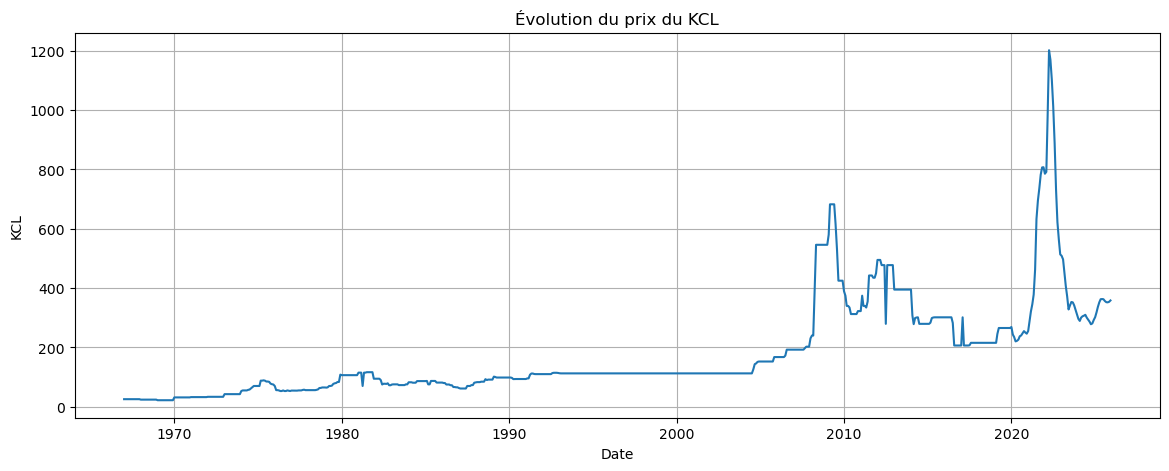

In [32]:
plt.figure(figsize=(14,5))

plt.plot(y)

plt.title("Évolution du prix du KCL")
plt.xlabel("Date")
plt.ylabel("KCL")

plt.grid(True)
plt.show()

In [33]:
result = adfuller(y)

print("ADF Statistic :", result[0])
print("p-value :", result[1])

ADF Statistic : -2.07864399839044
p-value : 0.25318820316219454


In [34]:
corr = df[
    [
        "KCL",
        "Phosphate",
        "DAP",
        "Gas_EUR",
        "Brent"
    ]
].corr()

print(corr["KCL"].sort_values(ascending=False))

KCL          1.000000
Gas_EUR      0.846527
DAP          0.833201
Phosphate    0.813736
Brent        0.798863
Name: KCL, dtype: float64


In [35]:
test_size = 24
train_size = len(df) - test_size

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

print("Train :", len(y_train))
print("Test :", len(y_test))

Train : 683
Test : 24


In [36]:
s=12
p=range(0,2)
d=range(0,2)
q=range(0,2)


P=range(0,2)
D=range(0,2)
Q=range(0,2)

best_rmse_mean = float("inf")
best_order = None
best_seasonal_order = None
grid_results = []

warnings.filterwarnings("ignore")


pdq=list(itertools.product(p,d,q))
seasonal_combos = [(P_val, D_val, Q_val, s) for P_val, D_val, Q_val in itertools.product(P, D, Q)]

#validation temporelle
valid_size=12
window=3
#grid search


for order in pdq:
    for seasonal_order in seasonal_combos:
        rmses=[]
        try:

            for w in range(window):
                end = len(y_train) - w *valid_size
                start_v = end - valid_size
                if start_v < 24:
                    continue

                y_tr_w = y_train.iloc[:start_v]
                y_val_w = y_train.iloc[start_v:end]
                X_tr_w = X_train.iloc[:start_v]
                X_val_w = X_train.iloc[start_v:end]

                model = SARIMAX(y_tr_w, exog=X_tr_w, order=order, seasonal_order=seasonal_order,
                                 enforce_invertibility=False, enforce_stationarity=False)
                results = model.fit(disp=False)

                fc = results.forecast(steps=len(y_val_w), exog=X_val_w)
                fc = pd.Series(np.asarray(fc), index=y_val_w.index)
                rmses.append(np.sqrt(mean_squared_error(y_val_w, fc)))

            if rmses:
                rmse_mean = np.mean(rmses)
                grid_results.append((order, seasonal_order, rmse_mean, len(rmses)))
                if rmse_mean < best_rmse_mean:
                    best_rmse_mean = rmse_mean
                    best_order = order
                    best_seasonal_order = seasonal_order

            

        except:
            continue
print("Meilleur modèle (moyenne 3 fenêtres) :", best_order, best_seasonal_order, best_rmse_mean)

Meilleur modèle (moyenne 3 fenêtres) : (1, 0, 1) (1, 1, 1, 12) 188.67193936955775


In [37]:
best_model=SARIMAX(y_train,exog=X_train,order=best_order,seasonal_order=best_seasonal_order,enforce_invertibility=False,enforce_stationarity=False)
model_fitted=best_model.fit(disp=False)
print(model_fitted.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                KCL   No. Observations:                  683
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 12)   Log Likelihood               -3017.795
Date:                            Mon, 17 Aug 2026   AIC                           6053.589
Time:                                    10:22:43   BIC                           6093.978
Sample:                                         0   HQIC                          6069.248
                                            - 683                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Phosphate      0.2732      0.038      7.275      0.000       0.200       0.347
DAP            0.2332      0.019   

In [38]:
#preduction sur le test
predictions=model_fitted.get_forecast(steps=len(y_test),exog=X_test)

In [39]:
y_pred = predictions.predicted_mean
conf_int = predictions.conf_int()

#réalignement des index temporels pour éviter les décalages graphiques
y_pred.index = y_test.index
conf_int.index = y_test.index

In [40]:
#metriques
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- RÉSULTATS DES MÉTRIQUES ---")
print(f"MAE   : {mae:.2f}")
print(f"RMSE  : {rmse:.2f}")
print(f"MAPE  : {mape * 100:.2f}%")
print(f"R²    : {r2:.4f}")


--- RÉSULTATS DES MÉTRIQUES ---
MAE   : 32.91
RMSE  : 38.02
MAPE  : 10.80%
R²    : -0.6048


In [41]:
print("BEST ORDER :", best_order)
print("BEST SEASONAL ORDER :", best_seasonal_order)
print("BEST RMSE MEAN (validation) :", best_rmse_mean)

BEST ORDER : (1, 0, 1)
BEST SEASONAL ORDER : (1, 1, 1, 12)
BEST RMSE MEAN (validation) : 188.67193936955775


In [42]:
naive_forecast = pd.Series(y_train.iloc[-1], index=y_test.index)
naive_seasonal = y.shift(12).iloc[train_size:].reindex(y_test.index)

rmse_naive = np.sqrt(mean_squared_error(y_test, naive_forecast))
rmse_naive_seasonal = np.sqrt(mean_squared_error(y_test, naive_seasonal))

print("\n--- BASELINES ---")
print(f"RMSE naïf simple     : {rmse_naive:.2f}")
print(f"RMSE naïf saisonnier : {rmse_naive_seasonal:.2f}")
print(f"RMSE SARIMAX         : {rmse:.2f}")


--- BASELINES ---
RMSE naïf simple     : 31.45
RMSE naïf saisonnier : 96.65
RMSE SARIMAX         : 38.02


In [43]:
print("BEST ORDER :", best_order)
print("BEST SEASONAL ORDER :", best_seasonal_order)
print("BEST RMSE MEAN (validation) :", best_rmse_mean)

print("\n--- RÉSULTATS DES MÉTRIQUES (TEST) ---")
print(f"MAE   : {mae:.2f}")
print(f"RMSE  : {rmse:.2f}")
print(f"MAPE  : {mape * 100:.2f}%")
print(f"R²    : {r2:.4f}")

print("\n--- BASELINES ---")
print(f"RMSE naïf simple     : {rmse_naive:.2f}")
print(f"RMSE naïf saisonnier : {rmse_naive_seasonal:.2f}")
print(f"RMSE SARIMAX         : {rmse:.2f}")

BEST ORDER : (1, 0, 1)
BEST SEASONAL ORDER : (1, 1, 1, 12)
BEST RMSE MEAN (validation) : 188.67193936955775

--- RÉSULTATS DES MÉTRIQUES (TEST) ---
MAE   : 32.91
RMSE  : 38.02
MAPE  : 10.80%
R²    : -0.6048

--- BASELINES ---
RMSE naïf simple     : 31.45
RMSE naïf saisonnier : 96.65
RMSE SARIMAX         : 38.02


In [ ]:
""""""""""""""""""""""""""""""""""""""""""""""""

In [44]:
test_size = 24
train_size = len(df) - test_size

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

print("Train :", len(y_train))
print("Test  :", len(y_test))

Train : 683
Test  : 24


In [48]:
# Modèle SARIMAX retenu

features = [
    "DAP",
    "Brent"
]

X = df[features]
y = df["KCL"]

# Séparation train/test
test_size = 24
train_size = len(df) - test_size

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

# Paramètres du modèle retenu
order = (1, 0, 1)
seasonal_order = (1, 0, 2, 12)

# Entraînement
model = SARIMAX(
    y_train,
    exog=X_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_invertibility=False,
    enforce_stationarity=False
)

model_fitted = model.fit(disp=False)

print("\n****** Modèle SARIMAX retenu ******")
print("Features :", features)
print("Order :", order)
print("Seasonal Order :", seasonal_order)

print(model_fitted.summary())


****** Modèle SARIMAX retenu ******
Features : ['DAP', 'Brent']
Order : (1, 0, 1)
Seasonal Order : (1, 0, 2, 12)
                                        SARIMAX Results                                        
Dep. Variable:                                     KCL   No. Observations:                  683
Model:             SARIMAX(1, 0, 1)x(1, 0, [1, 2], 12)   Log Likelihood               -3011.493
Date:                                 Mon, 17 Aug 2026   AIC                           6038.985
Time:                                         10:27:19   BIC                           6074.887
Sample:                                              0   HQIC                          6052.904
                                                 - 683                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------

In [49]:
#prev
forecast = model_fitted.get_forecast(steps=len(y_test),exog=X_test)
y_pred=forecast.predicted_mean
conf_int=forecast.conf_int()


In [50]:
#metriques
mae = mean_absolute_error( y_test,y_pred)

mse = mean_squared_error(y_test,y_pred)

rmse = np.sqrt(mse)

mape = mean_absolute_percentage_error(y_test,y_pred) * 100

r2 = r2_score(y_test,y_pred)
print("\n***performance finale sarimax****")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")



***performance finale sarimax****
MAE  : 17.30
MSE  : 432.33
RMSE : 20.79
MAPE : 5.55%
R²   : 0.5199


In [51]:
#sauvegarder le model
import joblib

model_path = r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\sarimax_final.pkl"

joblib.dump(model_fitted, model_path)

print("Modèle SARIMAX enregistré avec succès.")
print("Chemin :", model_path)

Modèle SARIMAX enregistré avec succès.
Chemin : C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\sarimax_final.pkl


In [52]:
import joblib

loaded_model = joblib.load(model_path)

print("Modèle chargé avec succès.")
print(loaded_model)

Modèle chargé avec succès.
